# 04 · Imbalance Handling and Hyper-parameter Tuning
### IT3091 Machine Learning · Group 2026-AI-42 · Modelling & comparison lead

**Questions.** (1) Does re-balancing the classes improve the **ranking** of clients, or only change the scale of the scores? (2) Which settings of the selected model family work best on time-aware folds?
**Input:** `artifacts/selection.json` from notebook 03. **Output:** `artifacts/tuned_pipeline.joblib` and `artifacts/tuned_params.json`.

Only about one contact in nine subscribes, so it is tempting to assume "imbalance needs SMOTE". We **test** it. All resampling happens **inside** the training part of each fold through an imbalanced-learn pipeline, never before splitting (that would copy information from validation rows into training).

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))          # lets the notebook import the project code in src/
warnings.filterwarnings("ignore")

import json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

from src.config import *
from src.data.prepare import load_modelling_data
from src.evaluation.metrics import cv_eval, summarise
from src.features.preprocessing import build_pipeline, HAS_IMB
from src.models.candidates import hgb, tuning_spaces
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170)
data = load_modelling_data()
X_train, y_train = data["X_train"], data["y_train"]
print("imbalanced-learn available:", HAS_IMB)

Loading local file: bank-additional-full.csv
Rows: raw 41,188 -> cleaned 41,176 | train 32,940 (rate 6.38%) | pilot 500 | test 7,736 (rate 32.41%)
imbalanced-learn available: True


---
## 1 · Class weights and SMOTE
Re-weighting and resampling mostly change the **scale** of predicted probabilities, not the **ranking**, so ranking metrics usually move little. The business decision that really depends on imbalance is the **cut-off**, which is set from economics and recent data in notebook 06.

In [2]:
imb = {
    "HGB: no weighting": build_pipeline(hgb(learning_rate=0.05, max_iter=300), scale=False),
    "HGB: class weights": build_pipeline(hgb(learning_rate=0.05, max_iter=300, class_weight="balanced"), scale=False),
    "LR: no weighting": build_pipeline(LogisticRegression(max_iter=3000, C=0.5), scale=True),
    "LR: class weights": build_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5), scale=True),
}
if HAS_IMB:
    imb["HGB: SMOTE"] = build_pipeline(hgb(learning_rate=0.05, max_iter=300), scale=False, smote=True)
imb_results = {k: cv_eval(p, X_train, y_train, 3) for k, p in imb.items()}
imb_mean, imb_txt = summarise(imb_results)
display(imb_txt[["roc_auc", "pr_auc", "lift_at_budget", "recall_at_budget"]])

,roc_auc,pr_auc,lift_at_budget,recall_at_budget
HGB: no weighting,0.676 +/- 0.003,0.207 +/- 0.009,2.212 +/- 0.07,0.442 +/- 0.014
HGB: class weights,0.67 +/- 0.002,0.209 +/- 0.009,2.226 +/- 0.041,0.445 +/- 0.008
LR: no weighting,0.669 +/- 0.01,0.203 +/- 0.011,2.145 +/- 0.069,0.429 +/- 0.014
LR: class weights,0.67 +/- 0.009,0.201 +/- 0.014,2.119 +/- 0.103,0.424 +/- 0.021
HGB: SMOTE,0.659 +/- 0.006,0.19 +/- 0.011,2.136 +/- 0.075,0.427 +/- 0.015


---
## 2 · SMOTE-Tomek: the resampler named in the proposal
SMOTE-Tomek first creates synthetic minority points (SMOTE), then removes **Tomek links** (majority / minority pairs that are each other's nearest neighbours) to clean the class boundary. It is applied **inside** each training fold only. We compare it with *no weighting* and *class weights* on **ranking quality and on probability quality**, because resampling is known to shift predicted probabilities: `score_inflation` far above 1.0 and a worse Brier score mean the model overstates every client's chance of subscribing.

*Caveat:* SMOTE on one-hot columns creates fractional category values, a known limitation of the method on mixed data.

,roc_auc,pr_auc,lift_at_budget,brier,mean_score,base_rate,score_inflation,fit_seconds
HGB: no weighting,0.6761,0.2067,2.2119,0.0552,0.0639,0.0638,1.0021,2.9712
HGB: class weights,0.6700,0.2086,2.2262,0.1922,0.4230,0.0638,6.6344,1.9561
HGB: SMOTE-Tomek,0.6622,0.1921,2.1143,0.0566,0.0747,0.0638,1.1718,6.5372
LR: no weighting,0.6693,0.2033,2.1452,0.0556,0.0637,0.0638,0.9993,0.3361
LR: class weights,0.6698,0.2006,2.1190,0.2109,0.4474,0.0638,7.0182,0.3166
LR: SMOTE-Tomek,0.6649,0.2023,2.1238,0.2068,0.4369,0.0638,6.8534,2.9406


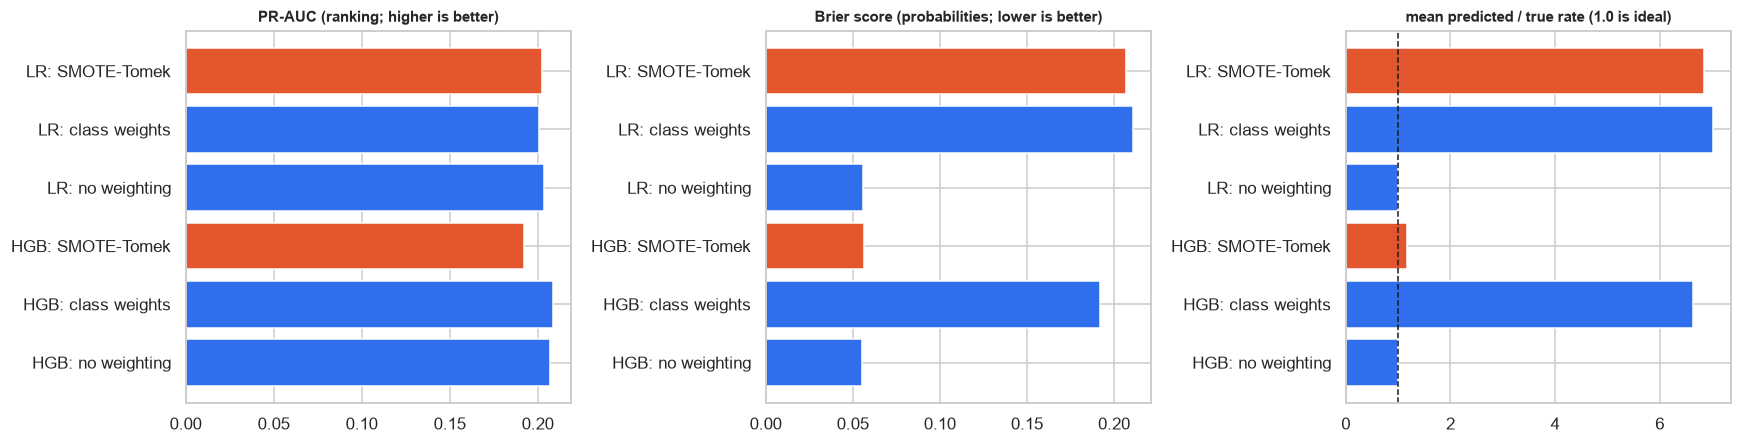

In [3]:
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import TomekLinks
smt_specs = {   # name -> (model factory, scale?, sampler factory or None)
    "HGB: no weighting": (lambda: hgb(learning_rate=0.05, max_iter=300), False, None),
    "HGB: class weights": (lambda: hgb(learning_rate=0.05, max_iter=300, class_weight="balanced"), False, None),
    "HGB: SMOTE-Tomek": (lambda: hgb(learning_rate=0.05, max_iter=300), False, lambda: SMOTETomek(random_state=SEED, tomek=TomekLinks(n_jobs=-1))),
    "LR: no weighting": (lambda: LogisticRegression(max_iter=3000, C=0.5), True, None),
    "LR: class weights": (lambda: LogisticRegression(max_iter=3000, C=0.5, class_weight="balanced"), True, None),
    "LR: SMOTE-Tomek": (lambda: LogisticRegression(max_iter=3000, C=0.5), True, lambda: SMOTETomek(random_state=SEED, tomek=TomekLinks(n_jobs=-1))),
}
smt_results = {k: cv_eval(build_pipeline(mf(), scale=sc, sampler=(sf() if sf else None)), X_train, y_train, 3) for k, (mf, sc, sf) in smt_specs.items()}
smt_mean = pd.DataFrame({k: v.mean() for k, v in smt_results.items()}).T
smt_mean["score_inflation"] = smt_mean["mean_score"] / smt_mean["base_rate"]       # 1.0 = scores average out to the true rate
cols = ["roc_auc", "pr_auc", "lift_at_budget", "brier", "mean_score", "base_rate", "score_inflation", "fit_seconds"]
display(smt_mean[cols].round(4))
smt_mean[cols].to_csv(TABLES_DIR / "imbalance_comparison.csv")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, col, ttl in zip(ax, ["pr_auc", "brier", "score_inflation"], ["PR-AUC (ranking; higher is better)", "Brier score (probabilities; lower is better)", "mean predicted / true rate (1.0 is ideal)"]):
    a.barh(smt_mean.index, smt_mean[col], color=[C_WARN if "SMOTE" in k else C_MAIN for k in smt_mean.index]); a.set_title(ttl, fontsize=10)
ax[2].axvline(1, color="k", ls="--", lw=1)
plt.tight_layout(); save_fig("imbalance_comparison")

**How to read it.** Two separate questions. *Ranking*: do `roc_auc`, `pr_auc` and `lift_at_budget` move? Usually barely. *Probabilities*: is `score_inflation` near 1.0? Class weights and resampling tell the model the minority class is more common than it is, so their scores cannot be compared with the economic break-even `c / v` of notebook 06 without recalibration, which is why that notebook recalibrates the base rate from recent labelled calls. **Decision rule (decision D14):** prefer the simpler option (no resampling) unless SMOTE-Tomek improves the *ranking*.

---
## 3 · Hyper-parameter tuning of the selected family
The family comes from notebook 03 (forward-chaining PR-AUC). The search uses **forward-chaining folds inside the training period** (`TimeSeriesSplit`, 3 splits) and a randomised search, so the tuned settings are chosen for the setting that matters, predicting the future from the past. The test period is **not** touched.

In [4]:
best_family = json.loads((ARTIFACTS_DIR / "selection.json").read_text())["best_family"]
grid, factory = tuning_spaces()[best_family]
n_combos = int(np.prod([len(v) for v in grid.values()]))
search = RandomizedSearchCV(factory(), grid, n_iter=min(12, n_combos), scoring="average_precision", cv=TimeSeriesSplit(n_splits=3),
                            random_state=SEED, n_jobs=-1, refit=True)
search.fit(X_train, y_train)
print("Family tuned                :", best_family)
print("Best forward-chaining PR-AUC:", round(search.best_score_, 4))
print("Best params                 :", search.best_params_)
res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(res[["rank_test_score", "mean_test_score", "std_test_score"] + [c for c in res.columns if c.startswith("param_")]].head(8).round(4))

Family tuned                : Logistic regression
Best forward-chaining PR-AUC: 0.1044
Best params                 : {'model__class_weight': None, 'model__C': 3}


,rank_test_score,mean_test_score,std_test_score,param_model__class_weight,param_model__C
10,1,0.1044,0.0624,NaN,3.0
8,2,0.1036,0.0614,NaN,1.0
6,3,0.0969,0.0622,NaN,0.3
11,4,0.0945,0.0580,balanced,3.0
9,5,0.0935,0.0568,balanced,1.0
7,6,0.0914,0.0540,balanced,0.3
5,7,0.0876,0.0484,balanced,0.1
4,8,0.0868,0.0461,NaN,0.1


In [5]:
best_pipe = search.best_estimator_
TUNED_NAME = "Tuned " + best_family
joblib.dump(best_pipe, ARTIFACTS_DIR / "tuned_pipeline.joblib")
(ARTIFACTS_DIR / "tuned_params.json").write_text(json.dumps({"name": TUNED_NAME, "family": best_family,
                                                             "params": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v)) for k, v in search.best_params_.items()},
                                                             "cv_pr_auc": float(search.best_score_)}, indent=2))
print("Saved", TUNED_NAME, "to artifacts/tuned_pipeline.joblib")

Saved Tuned Logistic regression to artifacts/tuned_pipeline.joblib


**Honest reading.** A forward-chaining score of the best trial is the *selection* score, optimistically biased because the best of several trials was picked. It is **not** a performance estimate: the only unbiased estimate is the later hold-out in notebook 05, which was never used for any choice. If tuning improves little over the fixed settings of notebook 03, that is expected on a hard, drifting problem, and says the defaults were already reasonable.